# Week 3 Statistical Analysis and Hypothesis Testing

## Project
Statistical Analysis of Bank Marketing Campaigns Using Python and the objective is To use statistical tests to investigate customer characteristics and their relationship with term deposit subscriptions.


In [1]:
# import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Reload the dataset using the correct separator
df = pd.read_csv("../../data/bank-full.csv", sep=",")

# Display the column names
print(df.columns.tolist())

# Display the first five rows
df.head()

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## Hypothesis 1: Customer Age and Term Deposit Subscription

### Research Question
Is there a significant difference in the average age of customers who subscribed
to a term deposit and those who did not?

### Null Hypothesis (H₀)
There is no significant difference in the average age of the two groups.

### Alternative Hypothesis (H₁)
There is a significant difference in the average age of the two groups.

### Significance Level
We will use a significance level of 0.05 (5%).

### Statistical Test
Independent-samples t-test.

In [2]:
# Separate customers into two groups
subscribed = df[df["y"] == "yes"]["age"]
not_subscribed = df[df["y"] == "no"]["age"]

# Calculate summary statistics
print("CUSTOMERS WHO SUBSCRIBED")
print("Number of customers:", len(subscribed))
print("Average age:", round(subscribed.mean(), 2))
print("Standard deviation:", round(subscribed.std(), 2))

print("\nCUSTOMERS WHO DID NOT SUBSCRIBE")
print("Number of customers:", len(not_subscribed))
print("Average age:", round(not_subscribed.mean(), 2))
print("Standard deviation:", round(not_subscribed.std(), 2))

CUSTOMERS WHO SUBSCRIBED
Number of customers: 5289
Average age: 41.67
Standard deviation: 13.5

CUSTOMERS WHO DID NOT SUBSCRIBE
Number of customers: 39922
Average age: 40.84
Standard deviation: 10.17


In [3]:
# Performing the Hypothesis Test
# Perform Welch's independent-samples t-test

t_statistic, p_value = stats.ttest_ind(
    subscribed,
    not_subscribed,
    equal_var=False
)

# Display the test results
print("T-statistic:", round(t_statistic, 4))
print("P-value:", p_value)

# Set the significance level
alpha = 0.05

# Interpret the result
if p_value < alpha:
    print("\nReject the null hypothesis.")
    print("The difference in average age is statistically significant.")
else:
    print("\nFail to reject the null hypothesis.")
    print("There is insufficient evidence of a significant difference.")

T-statistic: 4.3183
P-value: 1.5971046743760392e-05

Reject the null hypothesis.
The difference in average age is statistically significant.


## Results and Interpretation

The t-test returned a p-value of 0.00001597, which is below the
significance level of 0.05. Therefore, we reject the null hypothesis.

Customers who subscribed had an average age of 41.67 years, compared
to 40.84 years for those who did not subscribe.

This shows a statistically significant difference in the average age
of the two groups. However, the difference is small, and age alone
cannot explain whether a customer will subscribe.

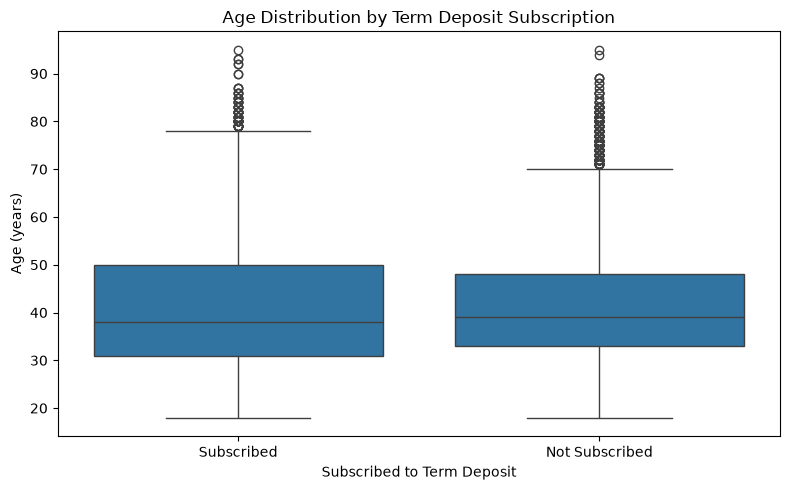

In [4]:
# Compare the age distributions of the two groups
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="y",
    y="age",
    order=["yes", "no"]
)

plt.title("Age Distribution by Term Deposit Subscription")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Age (years)")
plt.xticks([0, 1], ["Subscribed", "Not Subscribed"])
plt.tight_layout()

# Save the chart
plt.savefig("../charts/hypothesis1_age_boxplot.png", dpi=300)

plt.show()

## Hypothesis 2: Job Type and Term Deposit Subscription

### Research Question
Is there an association between a customer's job type and term deposit subscription status?

### Null Hypothesis (H₀)
Job type and subscription status are independent.

### Alternative Hypothesis (H₁)
Job type and subscription status are associated.

### Statistical Test
Chi-square test of independence, using a significance level of 0.05.

In [5]:
# Create a table of job types and subscription status
job_table = pd.crosstab(df["job"], df["y"])

# Display the table
print("Job Type vs Subscription Status")
display(job_table)

# Perform the Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(job_table)

# Display the results
print("\nChi-square statistic:", round(chi2, 4))
print("P-value:", p_value)
print("Degrees of freedom:", dof)

# Interpret the result
if p_value < 0.05:
    print("\nReject the null hypothesis.")
    print("Job type is significantly associated with subscription status.")
else:
    print("\nFail to reject the null hypothesis.")
    print("There is insufficient evidence of an association.")

Job Type vs Subscription Status


y,no,yes
job,,
admin.,4540,631
blue-collar,9024,708
entrepreneur,1364,123
housemaid,1131,109
management,8157,1301
retired,1748,516
self-employed,1392,187
services,3785,369
student,669,269



Chi-square statistic: 836.1055
P-value: 3.337121944935502e-172
Degrees of freedom: 11

Reject the null hypothesis.
Job type is significantly associated with subscription status.


## Results and Interpretation

The Chi-square test returned a p-value close to zero, which is below 0.05.
Therefore, we reject the null hypothesis.

The results suggest that job type is significantly associated with
term deposit subscription status. Subscription rates vary across job
categories, although this does not mean job type directly causes
a customer to subscribe.

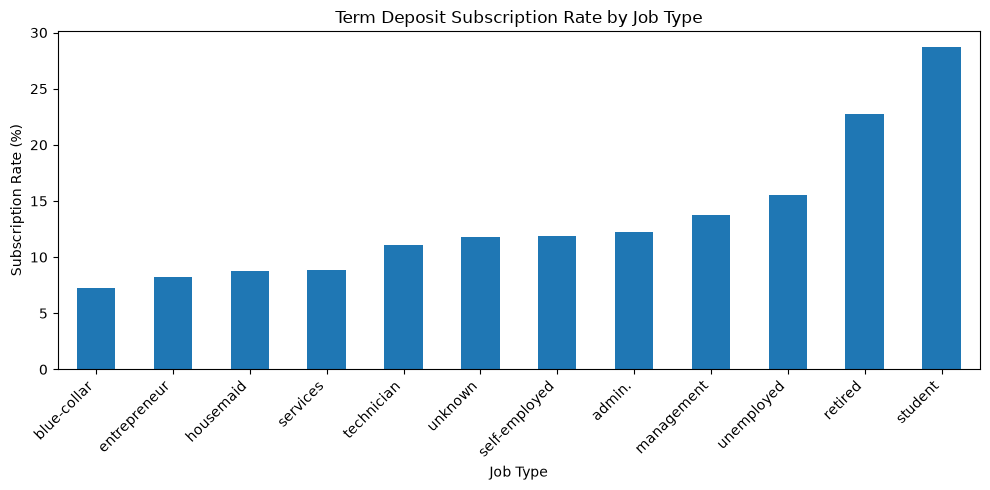

In [6]:
# Calculate subscription rates for each job type
job_subscription = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

# Create the bar chart
job_subscription["yes"].sort_values().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Term Deposit Subscription Rate by Job Type")
plt.xlabel("Job Type")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Save the chart
plt.savefig("../charts/hypothesis2_job_subscription.png", dpi=300)

plt.show()

## Job Subscription Rate Visualization

The bar chart compares term deposit subscription rates across different job categories. It helps identify which job groups have higher or lower subscription rates.

## Hypothesis 3: Marital Status and Term Deposit Subscription

### Research Question
Is marital status associated with term deposit subscription status?

### Null Hypothesis (H₀)
Marital status and subscription status are independent.

### Alternative Hypothesis (H₁)
Marital status and subscription status are associated.

### Statistical Test
Chi-square test of independence, with a significance level of 0.05.

In [7]:
# Create a table of marital status and subscription status
marital_table = pd.crosstab(df["marital"], df["y"])

# Display the table
print("Marital Status vs Subscription Status")
display(marital_table)

# Perform the Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(marital_table)

# Display the results
print("\nChi-square statistic:", round(chi2, 4))
print("P-value:", p_value)
print("Degrees of freedom:", dof)

# Interpret the result
if p_value < 0.05:
    print("\nReject the null hypothesis.")
    print("Marital status is significantly associated with subscription status.")
else:
    print("\nFail to reject the null hypothesis.")
    print("There is insufficient evidence of an association.")

Marital Status vs Subscription Status


y,no,yes
marital,,
divorced,4585,622
married,24459,2755
single,10878,1912



Chi-square statistic: 196.4959
P-value: 2.1450999986791792e-43
Degrees of freedom: 2

Reject the null hypothesis.
Marital status is significantly associated with subscription status.


## Results and Interpretation

The Chi-square test returned a very small p-value, below the significance
level of 0.05. Therefore, we reject the null hypothesis.

The results suggest that marital status is significantly associated
with term deposit subscription status. However, this does not mean
marital status directly causes a customer to subscribe.

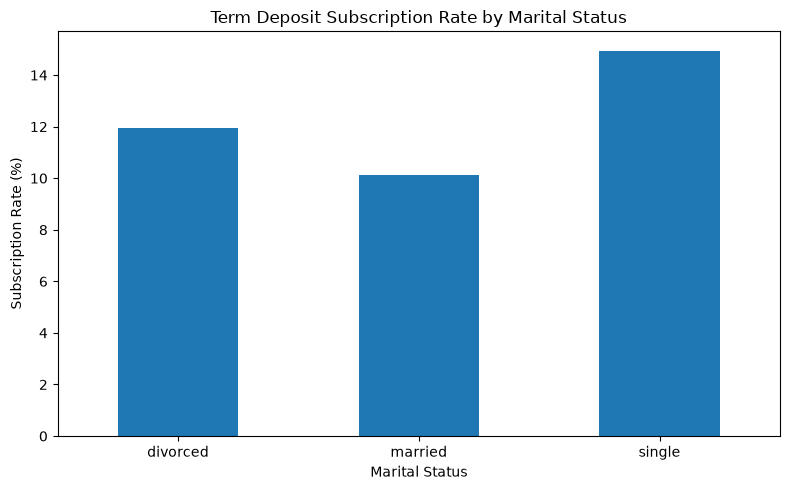

In [8]:
# Calculate subscription rates by marital status
marital_subscription = pd.crosstab(
    df["marital"],
    df["y"],
    normalize="index"
) * 100

# Create the bar chart
marital_subscription["yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Term Deposit Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

# Save the chart
plt.savefig("../charts/hypothesis3_marital_subscription.png", dpi=300)

plt.show()

## Overall Conclusion

This project used statistical tests to explore factors associated with term deposit subscriptions.

The t-test showed a significant difference in average age between customers who subscribed and those who did not. The Chi-square tests also found significant associations between subscription status and both job type and marital status.

Overall, the results suggest that customer characteristics are associated with subscription patterns. However, these findings do not prove that these characteristics directly cause customers to subscribe.